# IN6227 Assignment 1 — Variant 1
## Part 5: Final Evaluation on the Test Set

In [13]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

pd.set_option("display.width", 200)
RANDOM_STATE = 42
TARGET = "label"

test = pd.read_csv("test_clean.csv")
X_test = test.drop(columns=TARGET)
y_test = test[TARGET]
print("X_test:", X_test.shape, "| positives:", int(y_test.sum()), f"({y_test.mean():.1%})")

models = {
    "Logistic Regression": joblib.load("lr_model.joblib"),
    "Random Forest": joblib.load("rf_model.joblib"),
}

# Colours used for the two models in every figure
COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834"}

X_test: (13333, 15) | positives: 3168 (23.8%)


### 5.1 Predictions

In [15]:
proba, pred, pred_time = {}, {}, {}
for name, model in models.items():
    t0 = time.time()
    proba[name] = model.predict_proba(X_test)[:, 1]
    pred[name] = model.predict(X_test)
    pred_time[name] = time.time() - t0
    print(f"{name:20s} prediction time: {pred_time[name]:.3f} s | predicted 'yes': {pred[name].sum()}")

Logistic Regression  prediction time: 0.136 s | predicted 'yes': 5047
Random Forest        prediction time: 0.538 s | predicted 'yes': 4385


### 5.2 Test-set metrics

In [17]:
CV_F1 = {"Logistic Regression": 0.6596, "Random Forest": 0.6685}   # from Part 4, section 4.7

rows = []
baseline = np.zeros_like(y_test)
rows.append(["Baseline (always 'no')", accuracy_score(y_test, baseline),
             precision_score(y_test, baseline, zero_division=0), recall_score(y_test, baseline),
             f1_score(y_test, baseline), 0.5, np.nan])
for name in models:
    rows.append([name, accuracy_score(y_test, pred[name]), precision_score(y_test, pred[name]),
                 recall_score(y_test, pred[name]), f1_score(y_test, pred[name]),
                 roc_auc_score(y_test, proba[name]), CV_F1[name]])

metrics = pd.DataFrame(rows, columns=["model", "Accuracy", "Precision", "Recall", "F1",
                                      "ROC-AUC", "CV F1 (Part 4)"]).round(4)
metrics

,model,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1 (Part 4)
0,Baseline (always 'no'),0.7624,0.0000,0.0000,0.0000,0.5000,NaN
1,Logistic Regression,0.7844,0.5290,0.8428,0.6500,0.8871,0.6596
2,Random Forest,0.8117,0.5749,0.7958,0.6675,0.8902,0.6685


### 5.3 Is the F1 difference between the models real? (bootstrap)

In [19]:
rng = np.random.default_rng(RANDOM_STATE)
y = y_test.to_numpy()
p_lr, p_rf = pred["Logistic Regression"], pred["Random Forest"]
diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(y), len(y))
    diffs.append(f1_score(y[idx], p_rf[idx]) - f1_score(y[idx], p_lr[idx]))
diffs = np.array(diffs)
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"F1 difference (RF - LR): {f1_score(y, p_rf) - f1_score(y, p_lr):+.4f}")
print(f"95% bootstrap interval:  [{lo:+.4f}, {hi:+.4f}]")
print("RF better in", f"{(diffs > 0).mean():.1%}", "of the 1,000 resamples")

F1 difference (RF - LR): +0.0175
95% bootstrap interval:  [+0.0110, +0.0243]
RF better in 100.0% of the 1,000 resamples


### 5.4 Confusion matrices

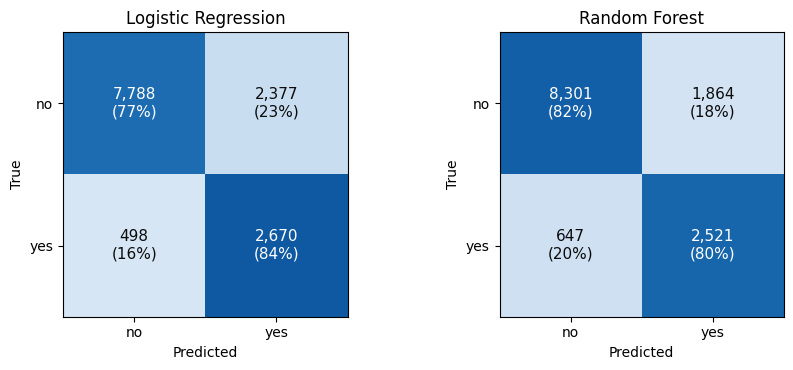

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, pred[name])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({share[i, j]:.0%})", ha="center", va="center",
                    fontsize=11, color="white" if share[i, j] > 0.5 else "#0b0b0b")
    ax.set_xticks([0, 1], ["no", "yes"])
    ax.set_yticks([0, 1], ["no", "yes"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("fig_confusion.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.5 ROC curves

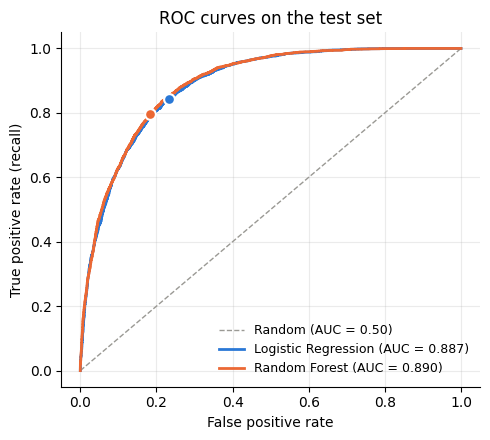

In [23]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="#9a9994", linewidth=1, label="Random (AUC = 0.50)")
for name in models:
    fpr, tpr, _ = roc_curve(y_test, proba[name])
    ax.plot(fpr, tpr, color=COLORS[name], linewidth=2,
            label=f"{name} (AUC = {roc_auc_score(y_test, proba[name]):.3f})")
    cm = confusion_matrix(y_test, pred[name])
    ax.scatter(cm[0, 1] / cm[0].sum(), cm[1, 1] / cm[1].sum(), s=60, color=COLORS[name],
               edgecolor="white", linewidth=1.5, zorder=3)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("fig_roc.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.6 Interpretability

In [25]:
def clean(names):
    return [n.split("__", 1)[1] for n in names]   # drop the 'num__' / 'cat__' prefix

lr = models["Logistic Regression"]
lr_coef = pd.Series(lr.named_steps["model"].coef_[0],
                    index=clean(lr.named_steps["pre"].get_feature_names_out()))
lr_top = lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(10)

rf = models["Random Forest"]
rf_imp = pd.Series(rf.named_steps["model"].feature_importances_,
                   index=clean(rf.named_steps["pre"].get_feature_names_out()))
rf_top = rf_imp.sort_values(ascending=False).head(10)

print("LR - 10 largest coefficients (absolute value):")
print(lr_top.round(3).to_string())
print("\nRF - 10 most important features:")
print(rf_top.round(3).to_string())

LR - 10 largest coefficients (absolute value):
mineral_type_Other        -2.653
mineral_type_Emerald       2.301
mineral_type_Diamond       2.186
stability_index            2.033
mineral_type_Slate        -1.781
mineral_type_Shale        -1.685
weather_pattern_Typhoon    1.550
mineral_type_Basalt       -1.550
mineral_type_Ruby          1.468
weather_pattern_Monsoon    1.283

RF - 10 most important features:
weather_pattern_Monsoon     0.148
composite_rank              0.105
aptitude_score              0.101
stability_index             0.070
instrument_Cello            0.070
performance_score           0.070
activity_duration           0.059
weather_pattern_Heatwave    0.052
load_ratio                  0.043
index_weight                0.031


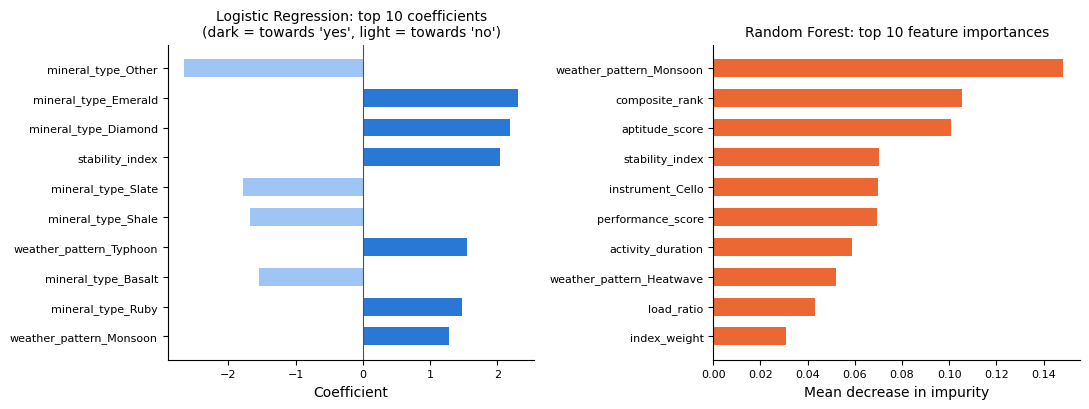

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
vals = lr_top[::-1]
ax.barh(vals.index, vals.values, color=[COLORS["Logistic Regression"] if v > 0 else "#9ec5f4" for v in vals],
        height=0.6)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_title("Logistic Regression: top 10 coefficients\n(dark = towards 'yes', light = towards 'no')", fontsize=10)
ax.set_xlabel("Coefficient")

ax = axes[1]
vals = rf_top[::-1]
ax.barh(vals.index, vals.values, color=COLORS["Random Forest"], height=0.6)
ax.set_title("Random Forest: top 10 feature importances", fontsize=10)
ax.set_xlabel("Mean decrease in impurity")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)
plt.tight_layout()
plt.savefig("fig_importance.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.7 Final comparison

In [28]:
fit_time = {"Logistic Regression": np.nan, "Random Forest": np.nan}
X_train = pd.read_csv("train_clean.csv").drop(columns=TARGET)
y_train = pd.read_csv("train_clean.csv")[TARGET]
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)       # same settings, same data -> same model; only for timing
    fit_time[name] = time.time() - t0

final = metrics.set_index("model").loc[list(models)].copy()
final["train time (s)"] = [fit_time[n] for n in models]
final["predict time (s)"] = [pred_time[n] for n in models]
final.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1 (Part 4),train time (s),predict time (s)
model,,,,,,,,
Logistic Regression,0.7844,0.5290,0.8428,0.6500,0.8871,0.6596,0.568,0.1363
Random Forest,0.8117,0.5749,0.7958,0.6675,0.8902,0.6685,8.374,0.5381


In [29]:
from sklearn.metrics import precision_recall_curve
for name in models:
    prec, rec, thr = precision_recall_curve(y_test, proba[name])
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    i = f1s[:-1].argmax()
    print(f"{name:20s} F1 at 0.5 = {f1_score(y_test, pred[name]):.4f} | "
          f"best F1 = {f1s[i]:.4f} at threshold {thr[i]:.3f}")

Logistic Regression  F1 at 0.5 = 0.6500 | best F1 = 0.6634 at threshold 0.595
Random Forest        F1 at 0.5 = 0.6675 | best F1 = 0.6688 at threshold 0.534


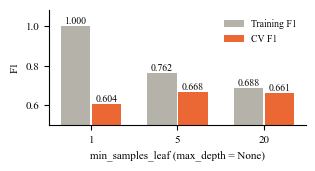

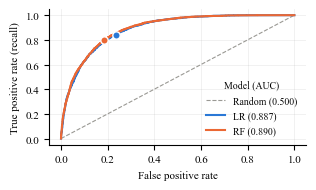

In [30]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
                     "font.size": 8})

# Fig. 1: effect of the stopping criterion min_samples_leaf (values from Part 4, section 4.6)
leaf = ["1", "5", "20"]
train_f1 = [0.9999, 0.7621, 0.6876]
cv_f1 = [0.6043, 0.6680, 0.6612]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(3.2, 1.75))
ax.bar(x - 0.18, train_f1, width=0.34, color="#b4b2a9", label="Training F1")
ax.bar(x + 0.18, cv_f1, width=0.34, color=COLORS["Random Forest"], label="CV F1")
for xi, (t, c) in enumerate(zip(train_f1, cv_f1)):
    ax.text(xi - 0.18, t + 0.01, f"{t:.3f}", ha="center", fontsize=7)
    ax.text(xi + 0.18, c + 0.01, f"{c:.3f}", ha="center", fontsize=7)
ax.set_xticks(x, leaf)
ax.set_xlabel("min_samples_leaf (max_depth = None)")
ax.set_ylabel("F1")
ax.set_ylim(0.5, 1.08)
ax.legend(frameon=False, fontsize=7, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("report_fig1_stopping.png", dpi=300, bbox_inches="tight")
plt.show()

# Fig. 2: ROC curves with the 0.5 operating points
fig, ax = plt.subplots(figsize=(3.2, 1.95))
ax.plot([0, 1], [0, 1], linestyle="--", color="#9a9994", linewidth=0.8, label="Random (0.500)")
for name in models:
    fpr, tpr, _ = roc_curve(y_test, proba[name])
    ax.plot(fpr, tpr, color=COLORS[name], linewidth=1.5,
            label=f"{'LR' if name.startswith('Log') else 'RF'} ({roc_auc_score(y_test, proba[name]):.3f})")
    cm = confusion_matrix(y_test, pred[name])
    ax.scatter(cm[0, 1] / cm[0].sum(), cm[1, 1] / cm[1].sum(), s=28, color=COLORS[name],
               edgecolor="white", linewidth=1, zorder=3)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(title="Model (AUC)", title_fontsize=7, frameon=False, fontsize=7, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25, linewidth=0.5)
plt.tight_layout()
plt.savefig("report_fig2_roc.png", dpi=300, bbox_inches="tight")
plt.show()